In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import random

print("All libraries imported successfully!")



All libraries imported successfully!


In [8]:
# Set project directory
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Dataset path
dataset_path = project_root / "data" / "processed" / "ted_talks_cleaned.csv"

# Interaction folder
interaction_folder = project_root / "data" / "interaction"
interaction_folder.mkdir(parents=True, exist_ok=True)

# Load cleaned TED Talks dataset
df = pd.read_csv(r"C:\Users\bhava\OneDrive\Desktop\TED TALKS RECOMMADATION\data\processed_output\ted_talks_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

df.head()

Dataset loaded successfully!
Dataset shape: (3921, 24)

Available columns:
['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript', 'title_clean', 'description_clean', 'transcript_clean', 'topics_clean', 'combined_text']


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,...,topics,related_talks,url,description,transcript,title_clean,description_clean,transcript_clean,topics_clean,combined_text
0,1,Al Gore sobre cómo evitar la crisis climática,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523396,2006-02-25,2006-06-27,TED2006,...,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,Con el mismo humor y humanidad que irradió en ...,Muchas gracias Chris. Y es en verdad un gran h...,al gore sobre c mo evitar la crisis clim tica,con el mismo humor y humanidad que irradi en u...,muchas gracias chris y es en verdad un gran ho...,alternative energy cars climate change culture...,al gore sobre c mo evitar la crisis clim tica ...
1,7,"David Pogue dice ""La Simplicidad Vende""",David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920803,2006-02-24,2006-06-27,TED2006,...,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,"El columnista del New York Times, David Pogue,...","Hola contestadora automática, mi vieja amiga. ...",david pogue dice la simplicidad vende,el columnista del new york times david pogue a...,hola contestadora autom tica mi vieja amiga ri...,computers entertainment interface design media...,david pogue dice la simplicidad vende el colum...
2,53,Un recorrido por la renovación urbana de la ma...,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664029,2006-02-26,2006-06-27,TED2006,...,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"En una charla altamente emotiva, la activista ...","Si están presentes aquí hoy, y estoy muy conte...",un recorrido por la renovaci n urbana de la ma...,en una charla altamente emotiva la activista g...,si est n presentes aqu hoy y estoy muy content...,macarthur grant activism business cities envir...,un recorrido por la renovaci n urbana de la ma...
3,66,Ken Robinson dice que las escuelas matan la cr...,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65052534,2006-02-25,2006-06-27,TED2006,...,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson plantea de manera entretenida...,"Buenos días. ¿Cómo están? Ha sido increíble, ¿...",ken robinson dice que las escuelas matan la cr...,sir ken robinson plantea de manera entretenida...,buenos d as c mo est n ha sido incre ble verda...,children creativity culture dance education pa...,ken robinson dice que las escuelas matan la cr...
4,92,Hans Rosling nos muestra las mejores estadísti...,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501766,2006-02-22,2006-06-27,TED2006,...,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,Una manera única de presentar datos. Con la en...,"Hace unos 10 años, emprendí la tarea de enseña...",hans rosling nos muestra las mejores estad sti...,una manera nica de presentar datos con la ener...,hace unos 10 a os emprend la tarea de ense ar ...,africa asia google demo economics global issue...,hans rosling nos muestra las mejores estad sti...


In [9]:
# Find the title column automatically
possible_title_columns = [
    "title", "Title", "talk_title", "Talk Title",
    "name", "Name"
]

title_col = next(
    (col for col in possible_title_columns if col in df.columns),
    None
)

if title_col is None:
    raise ValueError(
        "Title column not found. Check df.columns and set title_col manually."
    )

# Select 10 unique TED Talks
talks_df = (
    df[[title_col]]
    .dropna()
    .drop_duplicates()
    .head(10)
    .reset_index(drop=True)
)

# Create unique TED Talk IDs
talks_df["talk_id"] = [
    f"TALK_{i:03d}" for i in range(1, len(talks_df) + 1)
]

talks_df = talks_df[["talk_id", title_col]]

print("Selected TED Talks:")
display(talks_df)

Selected TED Talks:


,talk_id,title
0,TALK_001,Al Gore sobre cómo evitar la crisis climática
1,TALK_002,"David Pogue dice ""La Simplicidad Vende"""
2,TALK_003,Un recorrido por la renovación urbana de la ma...
3,TALK_004,Ken Robinson dice que las escuelas matan la cr...
4,TALK_005,Hans Rosling nos muestra las mejores estadísti...
5,TALK_006,Julia Sweeney habla sobre abandonar a Dios
6,TALK_007,Joshua Prince-Ramus habla sobre la biblioteca ...
7,TALK_008,Dan Dennett responde a Rick Warren
8,TALK_009,Rick Warren acerca de una vida con propósito.
9,TALK_010,Jehane Noujaim inspira un día mundial de cine


In [10]:
# Create sample users
users = [
    "USER_001",
    "USER_002",
    "USER_003",
    "USER_004",
    "USER_005",
    "USER_006",
    "USER_007",
    "USER_008"
]

print("Total users:", len(users))

print("\nUser IDs:")
for user in users:
    print(user)

Total users: 8

User IDs:
USER_001
USER_002
USER_003
USER_004
USER_005
USER_006
USER_007
USER_008


In [11]:
# Set random seed for reproducible results
np.random.seed(42)
random.seed(42)

interaction_data = []

talk_ids = talks_df["talk_id"].tolist()

for user in users:

    # Randomly select talks for each user
    selected_talks = random.sample(
        talk_ids,
        k=random.randint(4, min(7, len(talk_ids)))
    )

    for talk in selected_talks:

        # Generate rating between 1 and 5
        rating = random.randint(1, 5)

        # Determine like or dislike
        if rating >= 4:
            like_status = "Like"
        elif rating <= 2:
            like_status = "Dislike"
        else:
            like_status = "Neutral"

        # Simulate watch history and bookmarks
        watched = True
        saved = random.choice([True, False])

        interaction_data.append({
            "user_id": user,
            "talk_id": talk,
            "rating": rating,
            "like_status": like_status,
            "watched": watched,
            "saved": saved
        })

# Convert to DataFrame
interactions_df = pd.DataFrame(interaction_data)

print("Simulated interaction dataset created!")
display(interactions_df.head(10))

Simulated interaction dataset created!


,user_id,talk_id,rating,like_status,watched,saved
0,USER_001,TALK_001,2,Dislike,True,True
1,USER_001,TALK_005,5,Like,True,True
2,USER_001,TALK_004,5,Like,True,False
3,USER_001,TALK_002,1,Dislike,True,True
4,USER_002,TALK_004,2,Dislike,True,False
5,USER_002,TALK_010,2,Dislike,True,False
6,USER_002,TALK_001,5,Like,True,False
7,USER_002,TALK_005,1,Dislike,True,True
8,USER_003,TALK_006,4,Like,True,True
9,USER_003,TALK_005,3,Neutral,True,False


In [12]:
interactions_df = interactions_df.merge(
    talks_df,
    on="talk_id",
    how="left"
)

# Arrange columns
interactions_df = interactions_df[
    [
        "user_id",
        "talk_id",
        title_col,
        "rating",
        "like_status",
        "watched",
        "saved"
    ]
]

print("Interaction dataset with TED Talk titles:")
display(interactions_df.head(10))

Interaction dataset with TED Talk titles:


,user_id,talk_id,title,rating,like_status,watched,saved
0,USER_001,TALK_001,Al Gore sobre cómo evitar la crisis climática,2,Dislike,True,True
1,USER_001,TALK_005,Hans Rosling nos muestra las mejores estadísti...,5,Like,True,True
2,USER_001,TALK_004,Ken Robinson dice que las escuelas matan la cr...,5,Like,True,False
3,USER_001,TALK_002,"David Pogue dice ""La Simplicidad Vende""",1,Dislike,True,True
4,USER_002,TALK_004,Ken Robinson dice que las escuelas matan la cr...,2,Dislike,True,False
5,USER_002,TALK_010,Jehane Noujaim inspira un día mundial de cine,2,Dislike,True,False
6,USER_002,TALK_001,Al Gore sobre cómo evitar la crisis climática,5,Like,True,False
7,USER_002,TALK_005,Hans Rosling nos muestra las mejores estadísti...,1,Dislike,True,True
8,USER_003,TALK_006,Julia Sweeney habla sobre abandonar a Dios,4,Like,True,True
9,USER_003,TALK_005,Hans Rosling nos muestra las mejores estadísti...,3,Neutral,True,False


In [13]:
interaction_file = (
    interaction_folder / "user_interactions.csv"
)

interactions_df.to_csv(
    interaction_file,
    index=False
)

print("Interaction dataset saved successfully!")
print(interaction_file)

Interaction dataset saved successfully!
c:\Users\bhava\OneDrive\Desktop\TED TALKS RECOMMADATION\data\interaction\user_interactions.csv


In [14]:
# Create user-item interaction matrix
user_item_matrix = interactions_df.pivot(
    index="user_id",
    columns="talk_id",
    values="rating"
)

print("User-Item Interaction Matrix:")
display(user_item_matrix)

User-Item Interaction Matrix:


talk_id,TALK_001,TALK_002,TALK_003,TALK_004,TALK_005,TALK_006,TALK_007,TALK_008,TALK_009,TALK_010
user_id,,,,,,,,,,
USER_001,2.0,1.0,NaN,5.0,5.0,NaN,NaN,NaN,NaN,NaN
USER_002,5.0,NaN,NaN,2.0,1.0,NaN,NaN,NaN,NaN,2.0
USER_003,4.0,1.0,5.0,NaN,3.0,4.0,NaN,5.0,5.0,NaN
USER_004,4.0,4.0,NaN,2.0,NaN,2.0,NaN,3.0,NaN,3.0
USER_005,NaN,3.0,3.0,2.0,NaN,2.0,NaN,3.0,NaN,3.0
USER_006,NaN,5.0,3.0,NaN,NaN,NaN,5.0,2.0,NaN,5.0
USER_007,5.0,5.0,NaN,NaN,NaN,NaN,4.0,2.0,1.0,NaN
USER_008,3.0,2.0,5.0,NaN,5.0,1.0,NaN,NaN,3.0,NaN


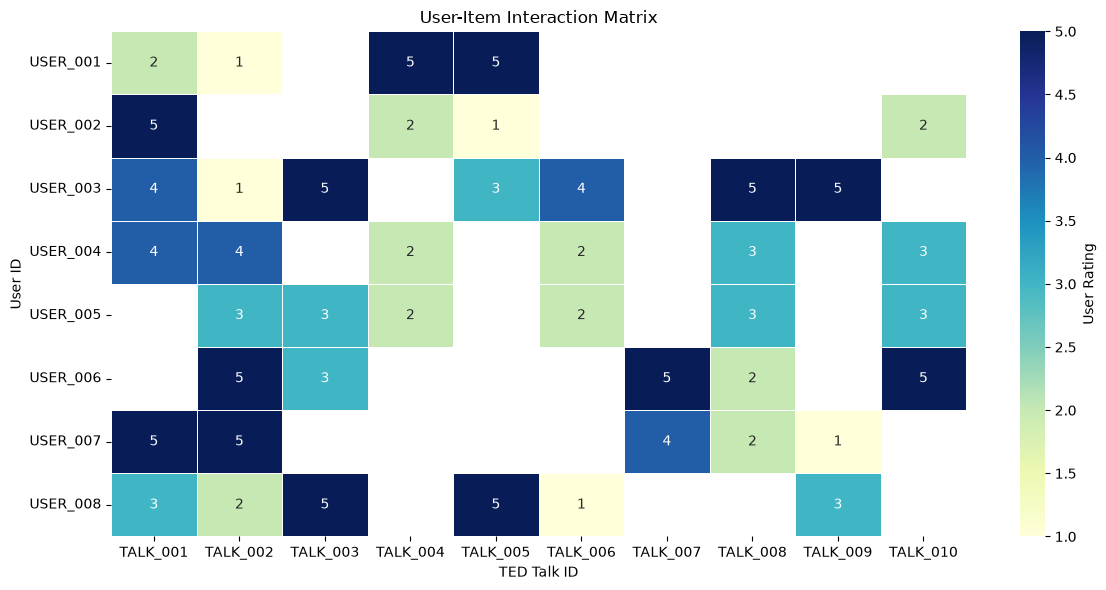

In [15]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    user_item_matrix,
    annot=True,
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "User Rating"}
)

plt.title("User-Item Interaction Matrix")
plt.xlabel("TED Talk ID")
plt.ylabel("User ID")

plt.tight_layout()
plt.show()

In [16]:
# Count unique users
total_users = interactions_df["user_id"].nunique()

# Count unique TED Talks
total_talks = interactions_df["talk_id"].nunique()

# Count total interactions
total_interactions = len(interactions_df)

print("Total Unique Users:", total_users)
print("Total Unique TED Talks:", total_talks)
print("Total User Interactions:", total_interactions)

Total Unique Users: 8
Total Unique TED Talks: 10
Total User Interactions: 43


In [17]:
highest_rated_talks = (
    interactions_df
    .groupby([ "talk_id", title_col ])["rating"]
    .mean()
    .reset_index()
    .sort_values(by="rating", ascending=False)
)

print("TED Talks with Highest Average Ratings:")
display(highest_rated_talks.head(5))

TED Talks with Highest Average Ratings:


,talk_id,title,rating
6,TALK_007,Joshua Prince-Ramus habla sobre la biblioteca ...,4.500000
2,TALK_003,Un recorrido por la renovación urbana de la ma...,4.000000
0,TALK_001,Al Gore sobre cómo evitar la crisis climática,3.833333
4,TALK_005,Hans Rosling nos muestra las mejores estadísti...,3.500000
9,TALK_010,Jehane Noujaim inspira un día mundial de cine,3.250000


In [18]:
user_rating_counts = (
    interactions_df
    .groupby("user_id")["rating"]
    .count()
    .sort_values(ascending=False)
    .reset_index(name="total_rated_talks")
)

print("Users who rated the most TED Talks:")
display(user_rating_counts)

Users who rated the most TED Talks:


,user_id,total_rated_talks
0,USER_003,7
1,USER_004,6
2,USER_008,6
3,USER_005,6
4,USER_006,5
5,USER_007,5
6,USER_001,4
7,USER_002,4


In [19]:
talk_interaction_counts = (
    interactions_df
    .groupby(["talk_id", title_col])
    .size()
    .reset_index(name="total_interactions")
    .sort_values(
        by="total_interactions",
        ascending=False
    )
)

print("TED Talks with the Most Interactions:")
display(talk_interaction_counts.head(10))

TED Talks with the Most Interactions:


,talk_id,title,total_interactions
1,TALK_002,"David Pogue dice ""La Simplicidad Vende""",7
0,TALK_001,Al Gore sobre cómo evitar la crisis climática,6
7,TALK_008,Dan Dennett responde a Rick Warren,5
2,TALK_003,Un recorrido por la renovación urbana de la ma...,4
4,TALK_005,Hans Rosling nos muestra las mejores estadísti...,4
3,TALK_004,Ken Robinson dice que las escuelas matan la cr...,4
5,TALK_006,Julia Sweeney habla sobre abandonar a Dios,4
9,TALK_010,Jehane Noujaim inspira un día mundial de cine,4
8,TALK_009,Rick Warren acerca de una vida con propósito.,3
6,TALK_007,Joshua Prince-Ramus habla sobre la biblioteca ...,2


User Preference Analysis:


like_status
Like       18
Dislike    15
Neutral    10
Name: count, dtype: int64

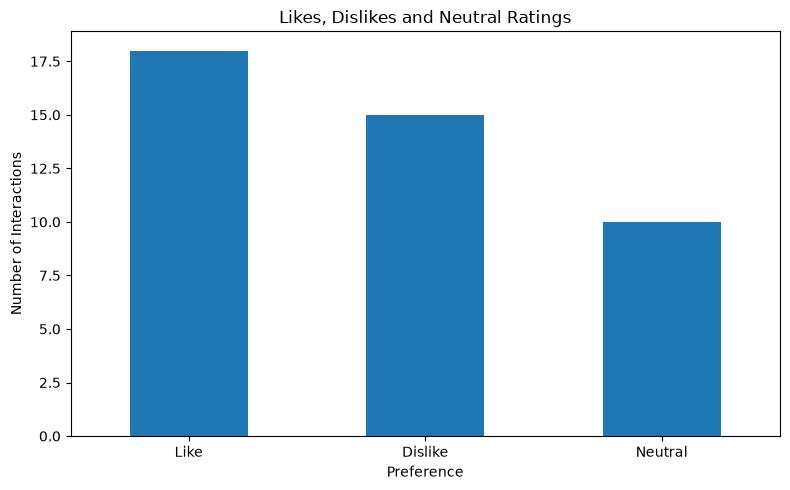

In [20]:
like_counts = interactions_df["like_status"].value_counts()

print("User Preference Analysis:")
display(like_counts)

like_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Likes, Dislikes and Neutral Ratings"
)

plt.xlabel("Preference")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Watch History:
watched
True    43
Name: count, dtype: int64

Saved TED Talks:
saved
False    22
True     21
Name: count, dtype: int64


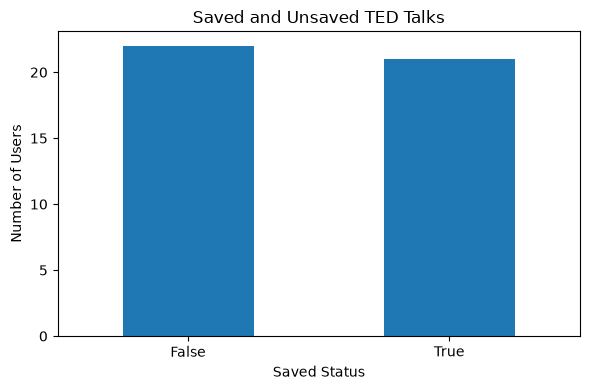

In [21]:
print("Watch History:")
print(interactions_df["watched"].value_counts())

print("\nSaved TED Talks:")
print(interactions_df["saved"].value_counts())

# Visualize saved talks
interactions_df["saved"].value_counts().plot(
    kind="bar",
    figsize=(6, 4),
    title="Saved and Unsaved TED Talks"
)

plt.xlabel("Saved Status")
plt.ylabel("Number of Users")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
missing_ratings = user_item_matrix.isnull().sum().sum()

total_possible_ratings = (
    user_item_matrix.shape[0] *
    user_item_matrix.shape[1]
)

print("Total Possible Ratings:", total_possible_ratings)
print("Missing Ratings:", missing_ratings)
print(
    "Percentage of Missing Ratings:",
    round(
        (missing_ratings / total_possible_ratings) * 100,
        2
    ),
    "%"
)

Total Possible Ratings: 80
Missing Ratings: 37
Percentage of Missing Ratings: 46.25 %


In [23]:
matrix_file = (
    interaction_folder / "user_item_matrix.csv"
)

user_item_matrix.to_csv(matrix_file)

print("User-item matrix saved successfully!")
print(matrix_file)

User-item matrix saved successfully!
c:\Users\bhava\OneDrive\Desktop\TED TALKS RECOMMADATION\data\interaction\user_item_matrix.csv
